In [1]:
import os
import pandas as pd
import numpy as np
from gensim.models import Word2Vec
from nltk.tokenize import word_tokenize
from keras.preprocessing.text import Tokenizer
import matplotlib.pyplot as plt

In [2]:
import re
import tensorflow as tf
from nltk.corpus import stopwords
from nltk.stem.wordnet import WordNetLemmatizer

In [3]:
from PIL import Image
from tqdm import tqdm

In [4]:
def clean_text(text):
    text = text.lower()
    return text

In [5]:
drs = os.listdir("train")
doc = {"id": [], "discourse_line": []}
for dr in drs:
    with open(f"train/{dr}") as file:
        text = [i.lower() for i in file.readlines() if i!="\n"]
        doc["discourse_line"].extend(text)
        doc["id"].extend([dr.replace(".txt","")]*len(text))
    
dataset = pd.DataFrame(doc)

In [6]:
corpus = pd.DataFrame(dataset.discourse_line.apply(lambda x: [word for word in word_tokenize(x)]))

In [7]:
corpus["id"]=dataset.id

In [8]:
tk = Tokenizer()
tk.fit_on_texts(dataset.discourse_line)

In [9]:
# Word2Vec Parameters 
dimension = 500
window = 8
max_length = int(np.quantile([len(doc) for doc in corpus], 0.95))
vocab_size = len(list(tk.word_index.items()))

In [10]:
modele = Word2Vec(corpus.discourse_line, vector_size=dimension, window=window)
words = modele.wv

In [11]:
embedding = np.zeros((vocab_size+1, dimension))
for word,idx in tk.word_index.items():
    try:
        embedding[idx] =  words[word]
    except:
        pass

In [12]:
len(tk.word_index.items())

61485

In [13]:
vocab={}
for word, idx in tk.word_index.items():
    try:
        vocab[word] = (np.mean(words[word])*0.5+0.5)*255
    except:
        vocab[word] = 0

In [14]:
def vectorize(text):
    liste = []
    for word in word_tokenize(text):
        try:
            liste.append(vocab[word])
        except:
            liste.append(0)
    return np.array(liste)

In [15]:
train_df = dataset.copy()
train_df.discourse_line = dataset.discourse_line.apply(vectorize)

In [16]:
train_df.head()

,id,discourse_line
0,0000D23A521A,"[122.6906564924866, 139.03302904218435, 128.61..."
1,0000D23A521A,"[126.38364056590945, 120.48637387342751, 125.7..."
2,0000D23A521A,"[128.9180216845125, 126.30332463188097, 125.34..."
3,0000D23A521A,"[129.45313580799848, 0.0, 132.42881669662893, ..."
4,00066EA9880D,"[122.2540323715657, 135.49508353695273, 131.27..."


In [17]:
def doc2image(data, width, height, margin):
    Image = np.zeros((height, width))
    for i,seq in enumerate(data):
        Image[i+margin+1,margin+1:(seq.shape[0]+margin+1)]=seq[0:(width-margin*2)+1]
    return Image

In [18]:
margin=2
image_data = []
height = dataset.id.value_counts().max()+2*margin
width = int(np.quantile(([len(i) for i in train_df.discourse_line]),0.95))+2*margin
indexs = list(train_df.id.unique())
for index in indexs:
    data = train_df[train_df.id==index].discourse_line.values
    image = doc2image(data, width, height, margin)
    image_data.append(image)

In [19]:
train_df=pd.DataFrame({"id":indexs, "Image":image_data})

In [20]:
import matplotlib

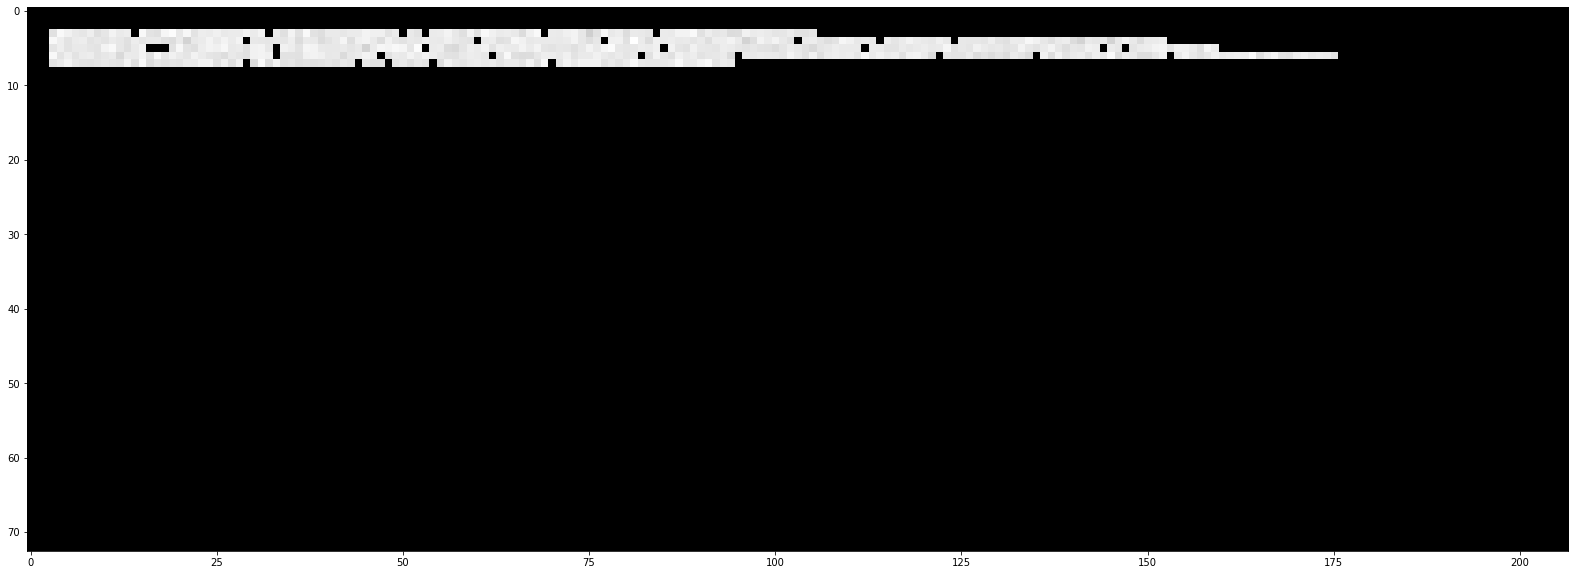

In [21]:
plt.figure(figsize=(48,10))
plt.imshow(train_df.Image[1], cmap="gray") 
matplotlib.image.imsave('name.png', train_df.Image[1], cmap="gray")

In [22]:
label_df = pd.read_csv("train.csv")
label_df.drop(["discourse_id", "discourse_start", "discourse_end", "discourse_type_num", "predictionstring"], axis=1, inplace=True)

In [23]:
label_df.discourse_text = label_df.discourse_text.apply(clean_text)

In [24]:
label_df.discourse_text = label_df.discourse_text.apply(lambda x: [word for word in word_tokenize(x)])

In [25]:
label_df.head()

,id,discourse_text,discourse_type
0,423A1CA112E2,"[modern, humans, today, are, always, on, their...",Lead
1,423A1CA112E2,"[they, are, some, really, bad, consequences, w...",Position
2,423A1CA112E2,"[some, certain, areas, in, the, united, states...",Evidence
3,423A1CA112E2,"[when, people, have, phones, ,, they, know, ab...",Evidence
4,423A1CA112E2,"[driving, is, one, of, the, way, how, to, get,...",Claim


In [26]:
def search_seq(value, searchval):
    solns = []
    for i in range(len(value)):
        values = np.array(value[i])
        N = len(searchval)
        possibles = np.where(values == searchval[0])[0]
        for p in possibles:
            check = values[p:p+N]
            if (len(check)==len(searchval)):
                if np.all(check == searchval):
                    solns.append([i, p, p+len(searchval)-1])
    return solns

In [27]:
position=[]
labels = []
for searchval,ids,label in zip(label_df.discourse_text, label_df.id, label_df.discourse_type):
    value = corpus[corpus.id==ids].discourse_line.to_list()
    solns = search_seq(value, searchval)
    if not solns:
        solns=[np.NaN]
    elif len(solns)>1:
        solns=[np.NaN]
    elif solns[0][2]>(width-2*margin):
        solns=[np.NaN]
        labels.append(label)

    position.append(*solns)
    
label_df["position"]=position    

In [28]:
label_df.dropna(inplace=True)

In [29]:
count=0
for i in tqdm(label_df.id.unique()):
    if i not in train_df.id.to_list():
        count+=1 
print("count =", count)

100%|██████████| 15477/15477 [00:07<00:00, 2094.22it/s]

count = 0


In [30]:
train_df.head()

,id,Image
0,0000D23A521A,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
1,00066EA9880D,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
2,000E6DE9E817,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
3,001552828BD0,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."
4,0016926B079C,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,..."


In [31]:
os.mkdir("dataset")

FileExistsError: [WinError 183] Impossible de créer un fichier déjà existant: 'dataset'

In [27]:
os.mkdir("dataset/images")

In [ ]:
os.mkdir("dataset/labels")

In [50]:
for elem,name in zip(train_df.Image, train_df.id):
    matplotlib.image.imsave(f'dataset/images/{name}.jpg', elem, cmap='gray')

In [32]:
label_df.head()

,id,discourse_text,discourse_type,position
0,423A1CA112E2,"[modern, humans, today, are, always, on, their...",Lead,"[1, 0, 46]"
1,423A1CA112E2,"[they, are, some, really, bad, consequences, w...",Position,"[1, 47, 62]"
2,423A1CA112E2,"[some, certain, areas, in, the, united, states...",Evidence,"[1, 63, 79]"
3,423A1CA112E2,"[when, people, have, phones, ,, they, know, ab...",Evidence,"[2, 0, 67]"
4,423A1CA112E2,"[driving, is, one, of, the, way, how, to, get,...",Claim,"[3, 0, 26]"


In [33]:
width

207

In [34]:
height

73

In [35]:
dict_mapping={j:i for i,j in enumerate(label_df.discourse_type.unique())}

In [36]:
dict_mapping

{'Lead': 0,
 'Position': 1,
 'Evidence': 2,
 'Claim': 3,
 'Concluding Statement': 4,
 'Counterclaim': 5,
 'Rebuttal': 6}

In [62]:
def label2txt(name):
    info = label_df[label_df.id==name]
    with open(f'dataset/labels/{name}.txt', 'a+') as file:
        for label,pos in zip(info.discourse_type, info.position):
            b_center_x = (pos[1] + pos[2] + 2*margin + 1) / 2 
            b_center_y = (pos[0] + pos[0] + 2*margin + 1) / 2
            b_width    = ((pos[2]+1) - pos[1])
            b_height   = 1
            # Normalise the co-ordinates by the dimensions of the image  
            b_center_x /= width
            b_center_y /= height
            b_width    /= width
            b_height   /= height
            file.write(f"{dict_mapping[label]} {b_center_x} {b_center_y} {b_width} {b_height}\n")

In [63]:
for doc in train_df.id:
    label2txt(doc)

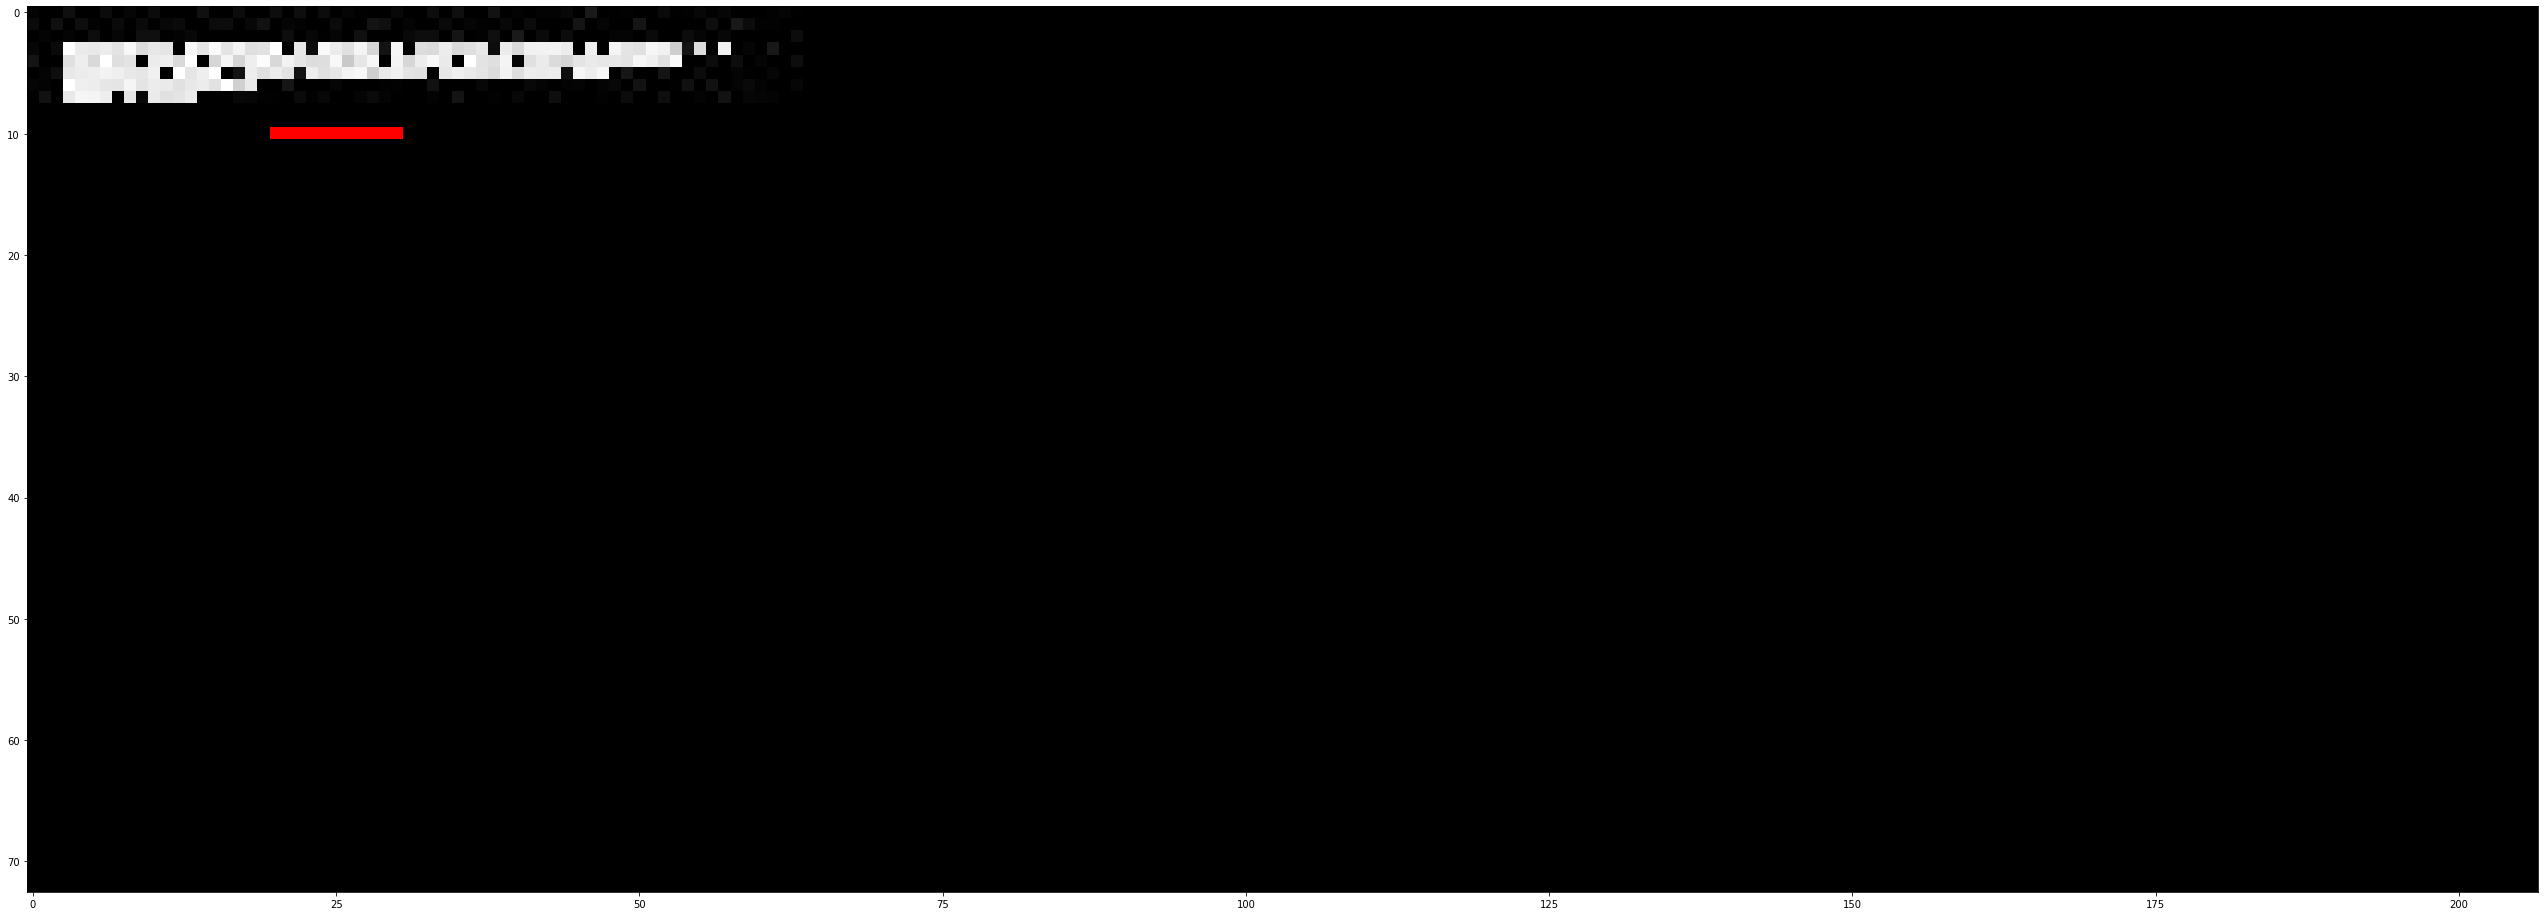

In [59]:
import cv2

image = plt.imread('dataset/images/FFFF80B8CC2F.jpg')
image.shape
image = cv2.rectangle(image, (20, 10), (30, 10), (255,0,0))
plt.figure(figsize=(45,20))
plt.imshow(image)